In [2]:
import pandas as pd
import os
from skimage.transform import resize
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

In [3]:
Categories =['Cat','Dog']
flat_data_arr =[]
target_arr = []
datadir = r"C:\Users\anshu\OneDrive\Desktop\Data"
for i in Categories:

    print(f'loading...category : {i}')
    path= os.path.join(datadir,i)
    for img in os.listdir(path):
        img_array = imread(os.path.join(path,img))
        img_resized = resize(img_array,(150,150,3))
        flat_data_arr.append(img_resized.flatten())
        target_arr.append(Categories.index(i))
    print(f'loaded category: {i} succesfully')

flat_data = np.array(flat_data_arr)
target = np.array(target_arr)

loading...category : Cat
loaded category: Cat succesfully
loading...category : Dog
loaded category: Dog succesfully


In [4]:
df = pd.DataFrame(flat_data)
df['Target']=target
df.shape

(124, 67501)

In [42]:
x = df.iloc[:,:-1]
y = df.iloc[:,-1]

In [46]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size = 0.20,random_state =77,stratify = y)

In [48]:
param_grid = {'C':[0.1,1,10,100],
              'gamma':[0.0001,0.001,0.1,1],
              'kernel':['rbf','poly']
             }

svc = svm.SVC(probability = True)

model = GridSearchCV(svc,param_grid)
    

In [50]:
model.fit(x_train,y_train)

GridSearchCV(estimator=SVC(probability=True),
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': [0.0001, 0.001, 0.1, 1],
                         'kernel': ['rbf', 'poly']})

In [51]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_pred,y_test)

print(f"The model is {accuracy *100} % accurate")

The model is 64.0 % accurate


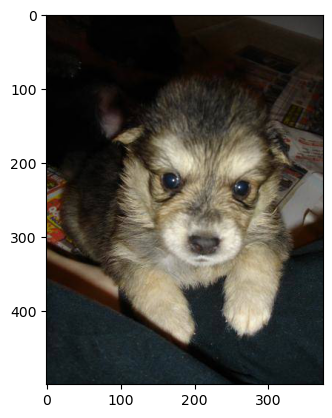

Cat = 4.137996427636825%
Dog = 95.86200357236318%
the predicted is :Dog


In [52]:
path = r"C:\Users\anshu\OneDrive\Desktop\dog.4871.jpg"
img = imread(path)
plt.imshow(img)
plt.show()
img_resize = resize(img,(150,150,3))
p =[img_resize.flatten()]
probability = model.predict_proba(p)
for ind,val in enumerate(Categories):
    print(f'{val} = {probability[0][ind]*100}%')
print("the predicted is :"+Categories[model.predict(p)[0]])

In [ ]:
00

In [54]:
import pickle 
with open(r'C:\Users\anshu\OneDrive\Desktop\Data\svm\model.pkl', 'wb') as f:
    pickle.dump(model, f)

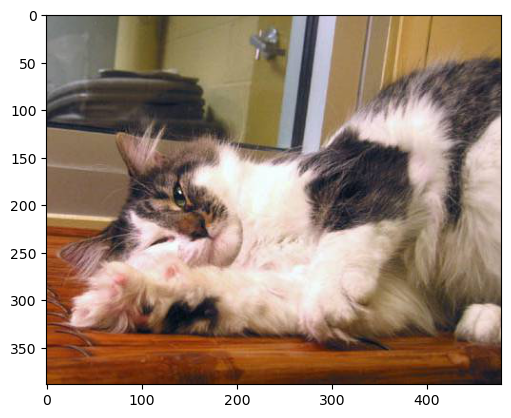

Cat = 97.54032941339813%
Dog = 2.459670586601888%
the predicted is :Cat


In [62]:
import pickle 
from skimage.transform import resize
from skimage.io import imread
import matplotlib.pyplot as plt
path = r"C:\Users\anshu\OneDrive\Desktop\Data\Cat\cat.4059.jpg"
img = imread(path)
plt.imshow(img)
plt.show()
img_resize = resize(img,(150,150,3))
p1 =[img_resize.flatten()]
model = pickle.load(open(r'C:\Users\anshu\OneDrive\Desktop\Data\svm\model.pkl',"rb"))
probability = model.predict_proba(p1)
for ind,val in enumerate(Categories):
    print(f'{val} = {probability[0][ind]*100}%')
print("the predicted is :"+Categories[model.predict(p1)[0]])

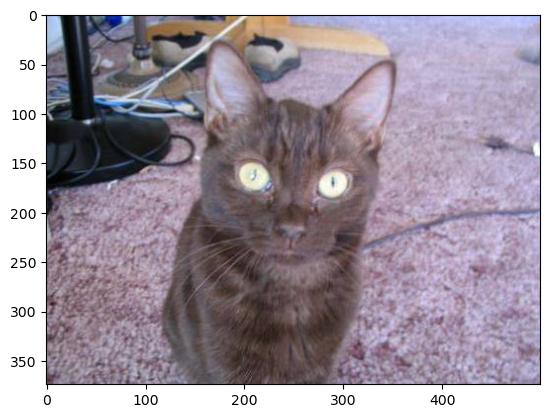

Cat = 97.53703407176168%
Dog = 2.462965928238323%
the predicted is :Cat


In [66]:
path = r"C:\Users\anshu\OneDrive\Desktop\Data\Cat\cat.4767.jpg"
img = imread(path)
plt.imshow(img)
plt.show()
img_resize = resize(img,(150,150,3))
p =[img_resize.flatten()]
probability = model.predict_proba(p)
for ind,val in enumerate(Categories):
    print(f'{val} = {probability[0][ind]*100}%')
print("the predicted is :"+Categories[model.predict(p)[0]])